# Reweighting along $\varepsilon_{go}$

In [1]:
import os, sys, json, warnings
import numpy as np, pandas as pd
from tqdm import tqdm
from matplotlib import pyplot as plt
from concurrent.futures import ProcessPoolExecutor, as_completed

while os.path.split(os.getcwd())[-1] != 'calvados-slim':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from src import utils, visualisation, constants
from src.analysis import mbar, slim

In [14]:
# --- Inputs ---
dGs = pd.read_csv('data/analysis/dGs.csv')
q_bounds = pd.read_csv('data/analysis/Q_bounds_calibrated.csv', index_col=0).iloc[:, 0]

# --- Configuration ---
TEMPERATURE  = 298.15
STRIDE       = 10                                   # frame subsampling (decorrelation + speed)
GRID         = np.round(np.arange(0.0, 10.001, 0.05), 2)

KD_WINDOW    = (1e-7, 1e-2)
DG_WINDOW    = tuple(np.sort(slim.dG(np.array(KD_WINDOW))))

# candidate selection
N_CANDIDATES = 10                                   # proposed eps_go per system
MIN_SPACING  = 0.1                                  # min gap between proposed eps_go
EXCLUDE_TOL  = MIN_SPACING                          # keep proposals off already-simulated eps_go

# error bars & reliability
ERRORS       = 'bootstrap'                          # 'bootstrap' (default, correlation-aware) or 'delta' -- interchangeable
N_BOOT       = 100                                  # bootstrap replicates (dominates runtime; lower for a quick pass)
BLOCK_SIZE   = 1                                    # STRIDE already decorrelates; raise to ~2*tau for raw frames
SEED         = 0
MIN_N_EFF_MINOR  = 5.0                                  # eff. samples of the rarer state for 'reliable'
MIN_NEFF     = 50.0
N_WORKERS    = max(1, (os.cpu_count() or 1) - 1)

systems = sorted(dGs.System.unique())

print(f'{len(systems)} systems | dG window {DG_WINDOW[0]:.1f}..{DG_WINDOW[1]:.1f} kJ/mol '
      f'(Kd {KD_WINDOW[0]:.0e} to {KD_WINDOW[1]:.0e} M) | errors={ERRORS}')

276 systems | dG window -40.0..-11.4 kJ/mol (Kd 1e-07 to 1e-02 M) | errors=bootstrap


In [4]:
# Getting sim dirs
sims = utils.get_scan_dirs('sim/1dp-idp')
sims['Frames'] = (sims.Path + '/' + sims.System + '.dcd').map(utils.get_dcd_frame_count)

# Filtering for unrun or too short simulations
sims = sims[sims['Frames'] > 100]
sims

,System,eps_go,Sampling mode,Replicate,Path,Frames
0,afadin-bcr,0.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=0.00/scan/rep1,10000.0
1,afadin-bcr,1.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=1.00/scan/rep1,10000.0
2,afadin-bcr,2.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=2.00/scan/rep1,10000.0
3,afadin-bcr,3.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=3.00/scan/rep1,10000.0
4,afadin-bcr,4.00,Scan,1,sim/1dp-idp/afadin-bcr/eps_go=4.00/scan/rep1,10000.0
...,...,...,...,...,...,...
3311,ywhab-mlxipl,2.75,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=2.75/scan/rep1,10000.0
3312,ywhab-mlxipl,2.85,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=2.85/scan/rep1,10000.0
3313,ywhab-mlxipl,3.00,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=3.00/scan/rep1,10000.0
3314,ywhab-mlxipl,4.00,Scan,1,sim/1dp-idp/ywhab-mlxipl/eps_go=4.00/scan/rep1,10000.0


## Reweight each system's scans along $\varepsilon_{go}$

Pool the converged states, build MBAR, and reweight onto the fine grid.
`N_eff_minor = N_eff · min(f, 1−f)` is the effective sample size of the *rarer* state — it collapses
in overlap gaps and at censored edges, and is the basis for both the value score and the reliability flag.

Command for removing local .DS_store files

`find . -name ".DS_Store" -type f -delete`

In [14]:
dGs_reweighted = {}
to_run = {}
for system_id, dGs_subset in dGs.groupby('System'):

    # Not treating mono state trajectories as converged
    to_run[system_id] = dGs_subset[~dGs_subset.traj_never_binds & ~dGs_subset.traj_never_unbinds]

with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {
        executor.submit(
            mbar.reweight_system, system_id, dGs_subset, sims, q_bounds[system_id], GRID,
            stride=STRIDE, temperature=TEMPERATURE, errors=ERRORS, n_boot=N_BOOT, block_size=BLOCK_SIZE, seed=SEED,
        ): system_id
        for system_id, dGs_subset in to_run.items()
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        dGs_reweighted[futures[future]] = future.result()

dGs_reweighted = pd.concat(dGs_reweighted).reset_index(level=1, drop=True)
dGs_reweighted.index.name = 'System'
dGs_reweighted = dGs_reweighted.sort_index(kind='stable')  # deterministic row order (completion order is not)

dGs_reweighted.to_csv('data/analysis/dGs_reweighted_full.csv')

100%|██████████| 276/276 [11:12<00:00,  2.44s/it]


Mean RMSD across systems: 1.28 kJ/mol


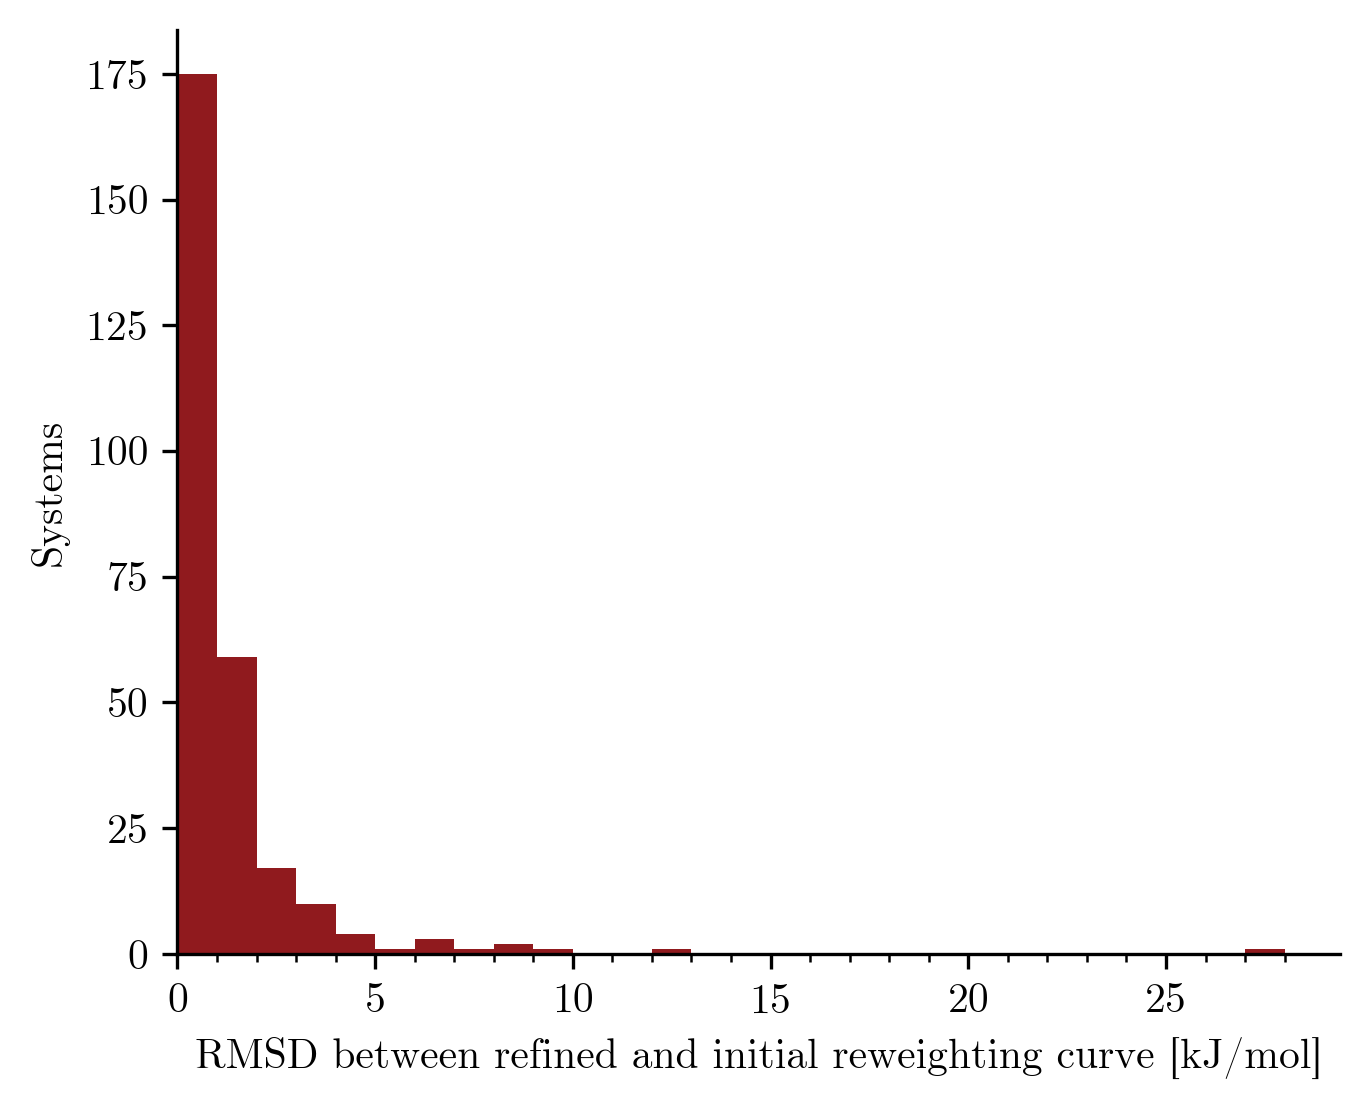

In [15]:
plt.figure(figsize=(5,4))

# RMSD after refinement
dGs_reweighted = pd.read_csv('data/analysis/dGs_reweighted_full.csv', index_col=0)
dGs_reweighted_initial = pd.read_csv('data/analysis/dGs_reweighted_initial.csv', index_col=0)
refinement_rmsds = (
    (dGs_reweighted - dGs_reweighted_initial)
    [(dGs_reweighted_initial.dG >= DG_WINDOW[0]) & (dGs_reweighted_initial.dG <= DG_WINDOW[1])]
    .groupby('System')
    .apply(lambda sub: 
            (sub['dG'][np.isfinite(sub['dG'])]
            **2)
            .sum()
            **0.5)
    .sort_values()
)
bins = np.arange(0, refinement_rmsds.max()+1, 1)
print(f"Mean RMSD across systems: {refinement_rmsds.mean():.2f} kJ/mol")
plt.hist(refinement_rmsds, bins=bins)
plt.xlim(0)
plt.xticks(bins,minor=True)
plt.xlabel("RMSD between refined and initial reweighting curve [kJ/mol]")
plt.ylabel("Systems")
plt.show()

## Suggesting refinement simulation candidates

### By weakest overlap link

A weak adjacent overlap $O_{i,i+1}$ means two consecutively-sampled $\varepsilon_{go}$ states barely
share configuration space, so any target between them rests on an unbridged MBAR extrapolation --
however many frames either state has (`N_eff`/`N_eff_minor` can look fine on both sides while the
midpoint is essentially unsupported). Proposing that midpoint directly repairs the gap, rather than
chasing wherever the fine-grid `N_eff_minor` happens to be lowest.

In [ ]:
# Diagnosing the MBAR overlap chain per system (separate loading pass -- dGs_reweighted doesn't carry overlap)
overlap_diagnostics = {}
to_run = {}
for system_id, dGs_subset in dGs.groupby('System'):
    # Not treating mono state trajectories as converged
    to_run[system_id] = dGs_subset[~dGs_subset.traj_never_binds & ~dGs_subset.traj_never_unbinds]
with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {
        executor.submit(
            mbar.overlap_system, system_id, dGs_subset, sims, q_bounds[system_id],
            stride=STRIDE, temperature=TEMPERATURE,
        ): system_id
        for system_id, dGs_subset in to_run.items()
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        overlap_diagnostics[futures[future]] = future.result()

# Prioritising candidates for refinement simulations
refinement_priority = []

for system_id, diagnostics in overlap_diagnostics.items():

    if system_id not in dGs_reweighted.index:  continue

    # Determining existing simulations
    existing = dGs[dGs['System'] == system_id]
    #existing = existing[existing.eps_go.isin(range(6))] # TEMP
    eps_go_lower_limit = existing[existing.traj_transitions == 0].eps_go.max() if (existing.traj_transitions == 0).any() else -np.inf
    eps_go_upper_limit = existing[existing.traj_transitions == 1].eps_go.min() if (existing.traj_transitions == 1).any() else np.inf
    reweighted_curve = dGs_reweighted.loc[[system_id]].reset_index(drop=True)   # duplicate 'System' index -> positional lookup only

    # Candidate eps_go = midpoint of every adjacent link, weakest overlap first
    links = sorted(diagnostics['adjacent_overlap'], key=lambda link: link[2])

    picked = []
    for eps_i, eps_j, overlap in links:
        candidate_eps_go = round(round(0.5 * (eps_i + eps_j) / 0.05) * 0.05, 2)

        # Looking up the reweighted dG at (closest to) the candidate eps_go
        nearest_pos = (reweighted_curve['eps_go'] - candidate_eps_go).abs().to_numpy().argmin()
        candidate = reweighted_curve.iloc[nearest_pos]

        # Only candidates within affinity window of interest
        if not (DG_WINDOW[0] <= candidate.dG <= DG_WINDOW[1]):  continue

        # Checking if too close to existing
        if any(abs(candidate_eps_go - e) < EXCLUDE_TOL for e in existing.eps_go):  continue

        # Check if expected not to converge
        if candidate_eps_go > eps_go_upper_limit:  continue
        if candidate_eps_go < eps_go_lower_limit:  continue

        # Checking if too close to previous pick
        if any(abs(candidate_eps_go - p) < MIN_SPACING for p in picked):    continue

        picked.append(candidate_eps_go)
        refinement_priority.append({
            'System': system_id, 'eps_go': candidate_eps_go, 'overlap': overlap,
            'dG_pred': candidate.dG, 'dG_pred_sigma': candidate.dG_sigma,
            'N_eff': candidate.N_eff, 'N_eff_minor': candidate.N_eff_minor,
        })

        if len(picked) >= N_CANDIDATES: break

refinement_priority = pd.DataFrame(refinement_priority)
refinement_priority.sort_values('overlap', ascending=True, inplace=True)
refinement_priority.reset_index(drop=True, inplace=True)

refinement_priority.to_csv('data/planning/refinement_priority_overlap.csv', index=False)
refinement_priority

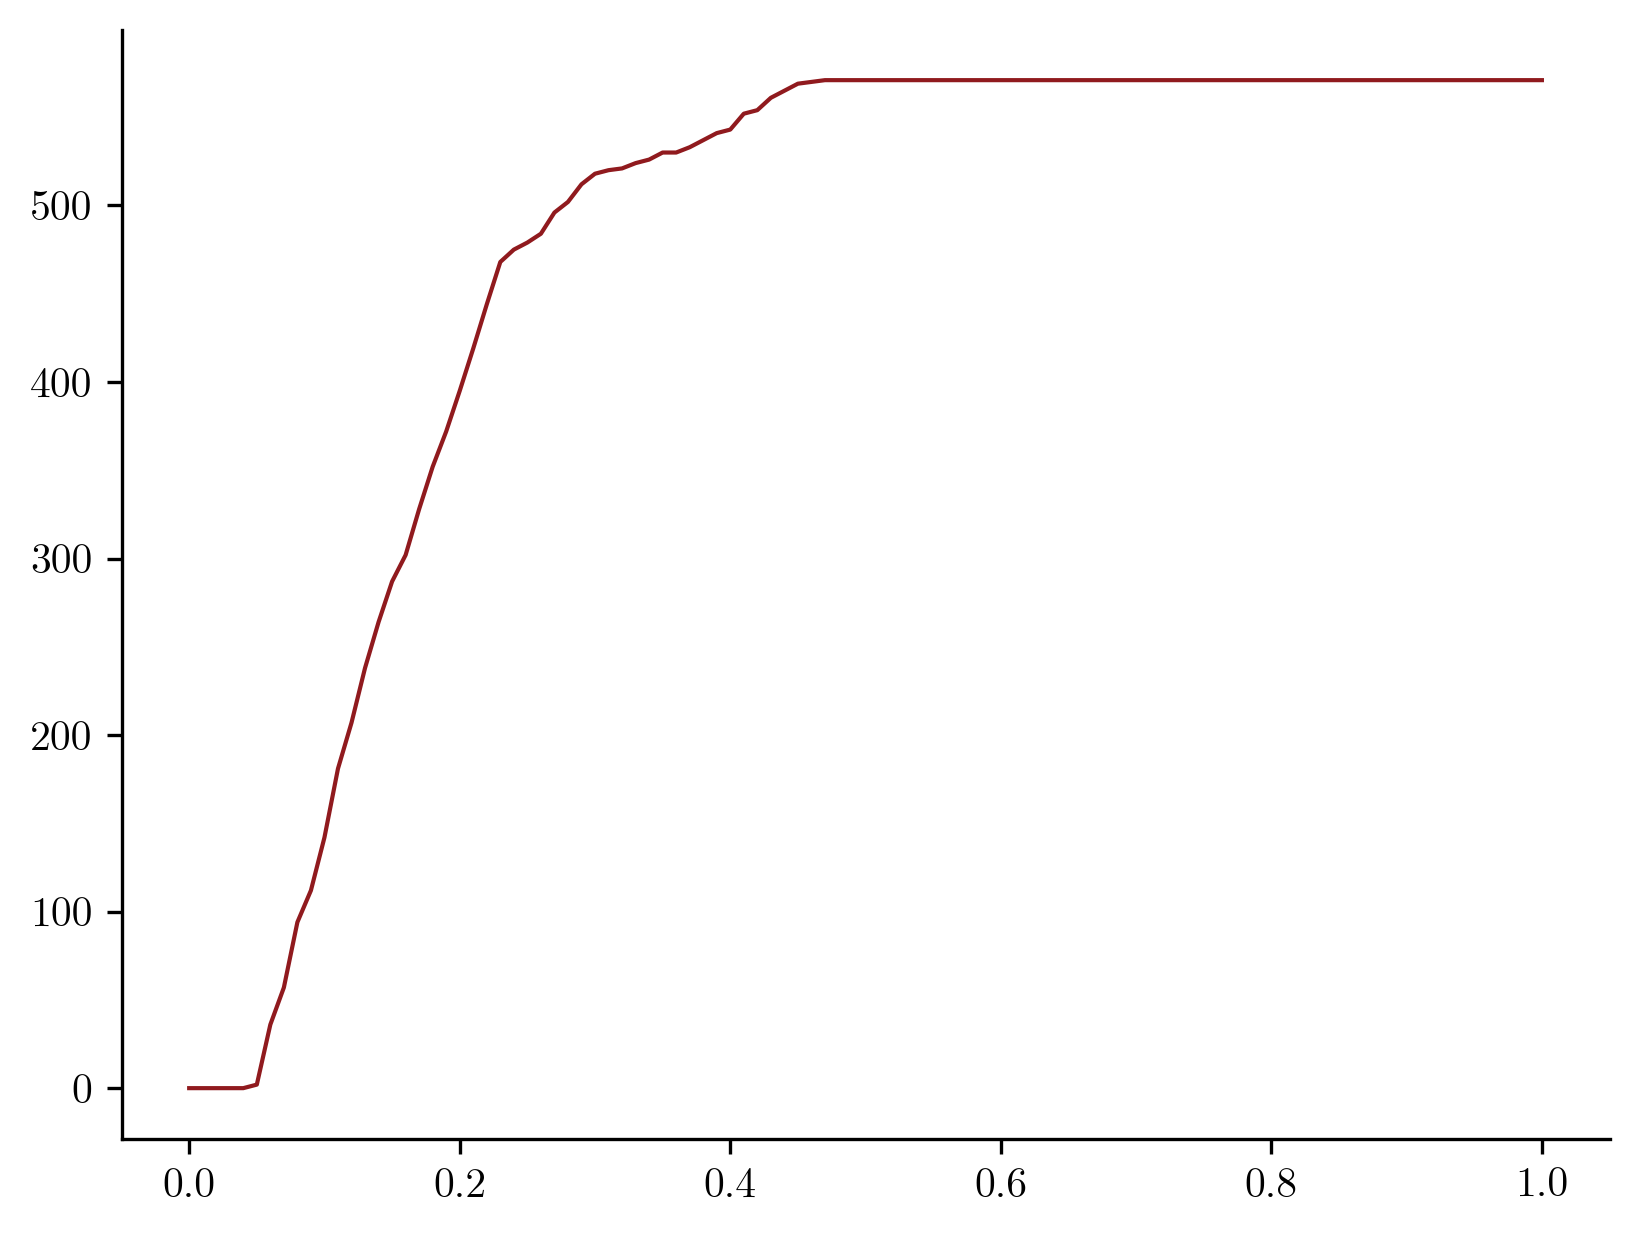

In [ ]:
plt.plot(np.linspace(0,1,101), (refinement_priority.overlap.values[:,np.newaxis] < np.linspace(0,1,101)).sum(axis=0))

### By effective frames of minor state

$$N_\text{eff}^\text{minor} = N_\text{eff}\cdot\min(f,\,1-f),$$

In [ ]:
# Prioritising candidates for refinement simulations
refinement_priority = []

for system_id, candidates in tqdm(dGs_reweighted.groupby(level=0)):

    # Determining existing simulations
    existing = dGs[dGs['System'] == system_id]
    eps_go_lower_limit = existing[existing.traj_transitions == 0].eps_go.max() if (existing.traj_transitions == 0).any() else -np.inf
    eps_go_upper_limit = existing[existing.traj_transitions == 1].eps_go.min() if (existing.traj_transitions == 1).any() else np.inf

    # Only candidates within affinity window of interest
    candidates = candidates[(candidates.dG >= DG_WINDOW[0]) & (candidates.dG <= DG_WINDOW[1])]
    candidates.rename({'dG': 'dG_pred', 'dG_sigma': 'dG_pred_sigma'}, axis=1, inplace=True)

    # See if any candidates remain
    if len(candidates) == 0:
        continue

    # Loop over candidates descendingly
    picked = [] 
    for _, candidate in candidates.sort_values('N_eff_minor', ascending=True).iterrows():

        # Checking if too close to existing
        if any(abs(candidate.eps_go - e) < EXCLUDE_TOL for e in existing.eps_go):  continue

        # Check if expected not to converge
        if candidate.eps_go > eps_go_upper_limit:  continue
        if candidate.eps_go < eps_go_lower_limit:  continue

        # Checking if too close to previous pick
        if any(abs(candidate.eps_go - p) < MIN_SPACING for p in picked):    continue

        picked.append(candidate.eps_go)

        if len(picked) >= N_CANDIDATES: break

    picked = candidates[candidates.eps_go.isin(picked)]
    refinement_priority.append(picked)

refinement_priority = pd.concat(refinement_priority)
refinement_priority.sort_values('N_eff_minor', ascending=True, na_position='last', inplace=True)
refinement_priority.reset_index(inplace=True)

refinement_priority.to_csv('data/planning/refinement_priority_neffminor.csv', index=False)


  0%|          | 0/276 [00:00<?, ?it/s]/var/folders/ls/l5m3kcsd4lddcv2284nfc4b40000gn/T/ipykernel_8851/4171782610.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidates.rename({'dG': 'dG_pred', 'dG_sigma': 'dG_pred_sigma'}, axis=1, inplace=True)
100%|██████████| 276/276 [00:00<00:00, 587.73it/s]


### By being far from existing eps_go

In [ ]:
# Prioritising candidates for refinement simulations
refinement_priority = []

for system_id, candidates in tqdm(dGs_reweighted.groupby(level=0)):

    # Determining existing simulations
    existing = dGs[dGs['System'] == system_id]
    eps_go_lower_limit = existing[existing.traj_transitions == 0].eps_go.max() if (existing.traj_transitions == 0).any() else -np.inf
    eps_go_upper_limit = existing[existing.traj_transitions == 1].eps_go.min() if (existing.traj_transitions == 1).any() else np.inf
    candidates['existing_sim'] = ((existing.dG >= DG_WINDOW[0]) & (existing.dG <= DG_WINDOW[1])).sum()

    # Only candidates within affinity window of interest
    candidates = candidates[(candidates.dG >= DG_WINDOW[0]) & (candidates.dG <= DG_WINDOW[1])]
    candidates.rename({'dG': 'dG_pred', 'dG_sigma': 'dG_pred_sigma'}, axis=1, inplace=True)

    # See if any candidates remain
    if len(candidates) == 0:
        continue

    # Ordering by distance to existing simulation eps_go
    dist_to_existing = np.abs(candidates['eps_go'].values[:,np.newaxis] - existing['eps_go'].values[np.newaxis,:])
    candidates_order = np.argsort(dist_to_existing.min(axis=1))[::-1]

    # Loop over candidates descendingly
    picked = []
    
    for _, candidate in candidates.iloc[candidates_order].iterrows():

        # Checking if too close to existing
        if any(abs(candidate.eps_go - e) < EXCLUDE_TOL for e in existing.eps_go):  continue

        # Check if expected not to converge
        if candidate.eps_go > eps_go_upper_limit:  continue
        if candidate.eps_go < eps_go_lower_limit:  continue

        # Checking if too close to previous pick
        if any(abs(candidate.eps_go - p) < MIN_SPACING for p in picked):    continue

        picked.append(candidate.eps_go)

        if len(picked) >= 2: break

    picked = candidates[candidates.eps_go.isin(picked)]
    refinement_priority.append(picked)

refinement_priority = pd.concat(refinement_priority)
refinement_priority.sort_values('existing_sim', inplace=True)
refinement_priority.reset_index(inplace=True)

refinement_priority.to_csv('data/planning/refinement_priority_distance.csv', index=False)

## Plotting

In [16]:
for system_id, reweighted_subset in tqdm(dGs_reweighted.groupby('System')):

    # Simulations
    dGs_system = dGs[dGs['System'] == system_id]
    dGs_converged = dGs_system[~dGs_system.traj_never_binds & ~dGs_system.traj_never_unbinds]
    dGs_unconverged = dGs_system[dGs_system.traj_never_binds | dGs_system.traj_never_unbinds]
    plt.errorbar(
        dGs_converged['eps_go'],
        dGs_converged['dG'],
        np.stack([dGs_converged['dG'] - dGs_converged['dG-1SEM'],  dGs_converged['dG+1SEM'] - dGs_converged['dG']]),
        color=visualisation.ku_red, ms=2, capsize=1, elinewidth=0.5, linewidth=0.5, fmt = 's', 
        label="Trajectory estimate"
    )
    plt.scatter(
        dGs_unconverged['eps_go'],
        np.where(dGs_unconverged['dG'] == np.inf, 0, dGs_unconverged['dG']),
        marker='x', c='red', s=15,
        label="Completely bound/unbound trajectory"
    )

    # Reweighting
    reweighted_subset = reweighted_subset[reweighted_subset['dG'] > -50]
    reweighted_subset_reliable = reweighted_subset[(reweighted_subset.N_eff_minor >= MIN_N_EFF_MINOR) & (reweighted_subset.N_eff >= MIN_NEFF)]
    plt.plot(
        reweighted_subset_reliable['eps_go'],
        reweighted_subset_reliable['dG'],
        alpha=1, c=visualisation.ku_red, lw=.5,
        label="Reliable reweighting"
    )
    plt.plot(
        reweighted_subset['eps_go'],
        reweighted_subset['dG'],
        alpha=0.8, ls='dotted', c=visualisation.ku_red, lw=.5,
        label="Unreliable reweighting"
    )
    plt.fill_between(
        reweighted_subset['eps_go'].values,
        (reweighted_subset['dG'] - reweighted_subset['dG_sigma']).values,
        (reweighted_subset['dG'] + reweighted_subset['dG_sigma']).values,
        alpha=0.2,
        label="Reweighting SEM (bootstrap)"
    )


    # SLiM range
    xlim = plt.xlim()
    plt.axhspan(*DG_WINDOW, color=visualisation.light_blue, alpha=0.2, label=r"ΔG°-range for $K_d$ = 10 mM to 100 nM")
    for Kd in np.geomspace(1,1e-12,13):
        dG = slim.dG(Kd)
        if (dG >= DG_WINDOW[0]) & (dG <= DG_WINDOW[-1]):
            plt.axhline(dG, *xlim, color=visualisation.light_blue, alpha=0.5, ls='dashed', lw=.5)

    # Decorations
    ylim = plt.ylim(-50,10)
    plt.ylabel(r'SLiM Affinity ΔG° [kJ/mol]')
    plt.xlabel(r'$\text{G}\bar{\text{o}}$ potential well depth $\varepsilon_{\text{G}\bar{\text{o}}}$ [kJ/mol]')
    plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
    plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
    plt.grid(which='major', alpha=0.3, linewidth=0.5)
    plt.grid(which='minor', alpha=0.1, linewidth=0.2)
    handles, labels = plt.gca().get_legend_handles_labels()
    order = [5,0,4,1,2,3]
    plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order],
               frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5,-0.15))
    plt.title(f'{system_id}')
    #plt.show()
    plt.savefig(f'figs/reweightings/{system_id}.png', bbox_inches='tight')
    plt.clf()
    
    

100%|██████████| 276/276 [00:55<00:00,  4.96it/s]


<Figure size 1920x1440 with 0 Axes>

## Reweighting subsets

In [15]:
# Coarse scan only
if True:
    
    dGs_reweighted = {}
    to_run = {}
    for system_id, dGs_subset in dGs[dGs['eps_go'].isin(range(6))].groupby('System'):

        # Not treating mono state trajectories as converged
        to_run[system_id] = dGs_subset[~dGs_subset.traj_never_binds & ~dGs_subset.traj_never_unbinds]

    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {
            executor.submit(
                mbar.reweight_system, system_id, dGs_subset, sims, q_bounds[system_id], GRID,
                stride=STRIDE, temperature=TEMPERATURE, errors=ERRORS, n_boot=N_BOOT, block_size=BLOCK_SIZE, seed=SEED,
            ): system_id
            for system_id, dGs_subset in to_run.items()
        }
        for future in tqdm(as_completed(futures), total=len(futures)):
            dGs_reweighted[futures[future]] = future.result()

    dGs_reweighted = pd.concat(dGs_reweighted).reset_index(level=1, drop=True)
    dGs_reweighted.index.name = 'System'
    dGs_reweighted = dGs_reweighted.sort_index(kind='stable')  # deterministic row order (completion order is not)

    dGs_reweighted.to_csv('data/analysis/dGs_reweighted_initial.csv')

100%|██████████| 276/276 [01:59<00:00,  2.31it/s]


In [16]:
# One good only    
if True:

    dGs_reweighted = {}
    to_run = {}
    for system_id, dGs_subset in dGs[dGs['eps_go'].isin(range(6))].groupby('System'):

        # Not treating mono state trajectories as converged
        dGs_converged = dGs_subset[~dGs_subset.traj_never_binds & ~dGs_subset.traj_never_unbinds]
        dGs_inrange = dGs_converged[(dGs_converged.dG >= DG_WINDOW[0]) & (dGs_converged.dG <= DG_WINDOW[1])]
        if len(dGs_inrange) == 0:
            dGs_inrange = dGs_converged
        to_run[system_id] = dGs_inrange.iloc[[np.argmin(np.abs(dGs_inrange.theta - 0.5))]]

    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = {
            executor.submit(
                mbar.reweight_system, system_id, dGs_subset, sims, q_bounds[system_id], GRID,
                stride=STRIDE, temperature=TEMPERATURE, errors=ERRORS, n_boot=N_BOOT, block_size=BLOCK_SIZE, seed=SEED,
            ): system_id
            for system_id, dGs_subset in to_run.items()
        }
        for future in tqdm(as_completed(futures), total=len(futures)):
            dGs_reweighted[futures[future]] = future.result()

    dGs_reweighted = pd.concat(dGs_reweighted).reset_index(level=1, drop=True)
    dGs_reweighted.index.name = 'System'
    dGs_reweighted = dGs_reweighted.sort_index(kind='stable')  # deterministic row order (completion order is not)

    dGs_reweighted.to_csv('data/analysis/dGs_reweighted_singular.csv')

100%|██████████| 276/276 [00:19<00:00, 14.07it/s]


### Comparison of techniques

In [25]:
dGs_reweighted_full = pd.read_csv('data/analysis/dGs_reweighted_full.csv')
dGs_reweighted_initial = pd.read_csv('data/analysis/dGs_reweighted_initial.csv')
dGs_reweighted_singular = pd.read_csv('data/analysis/dGs_reweighted_singular.csv')

<Axes: xlabel='dG'>

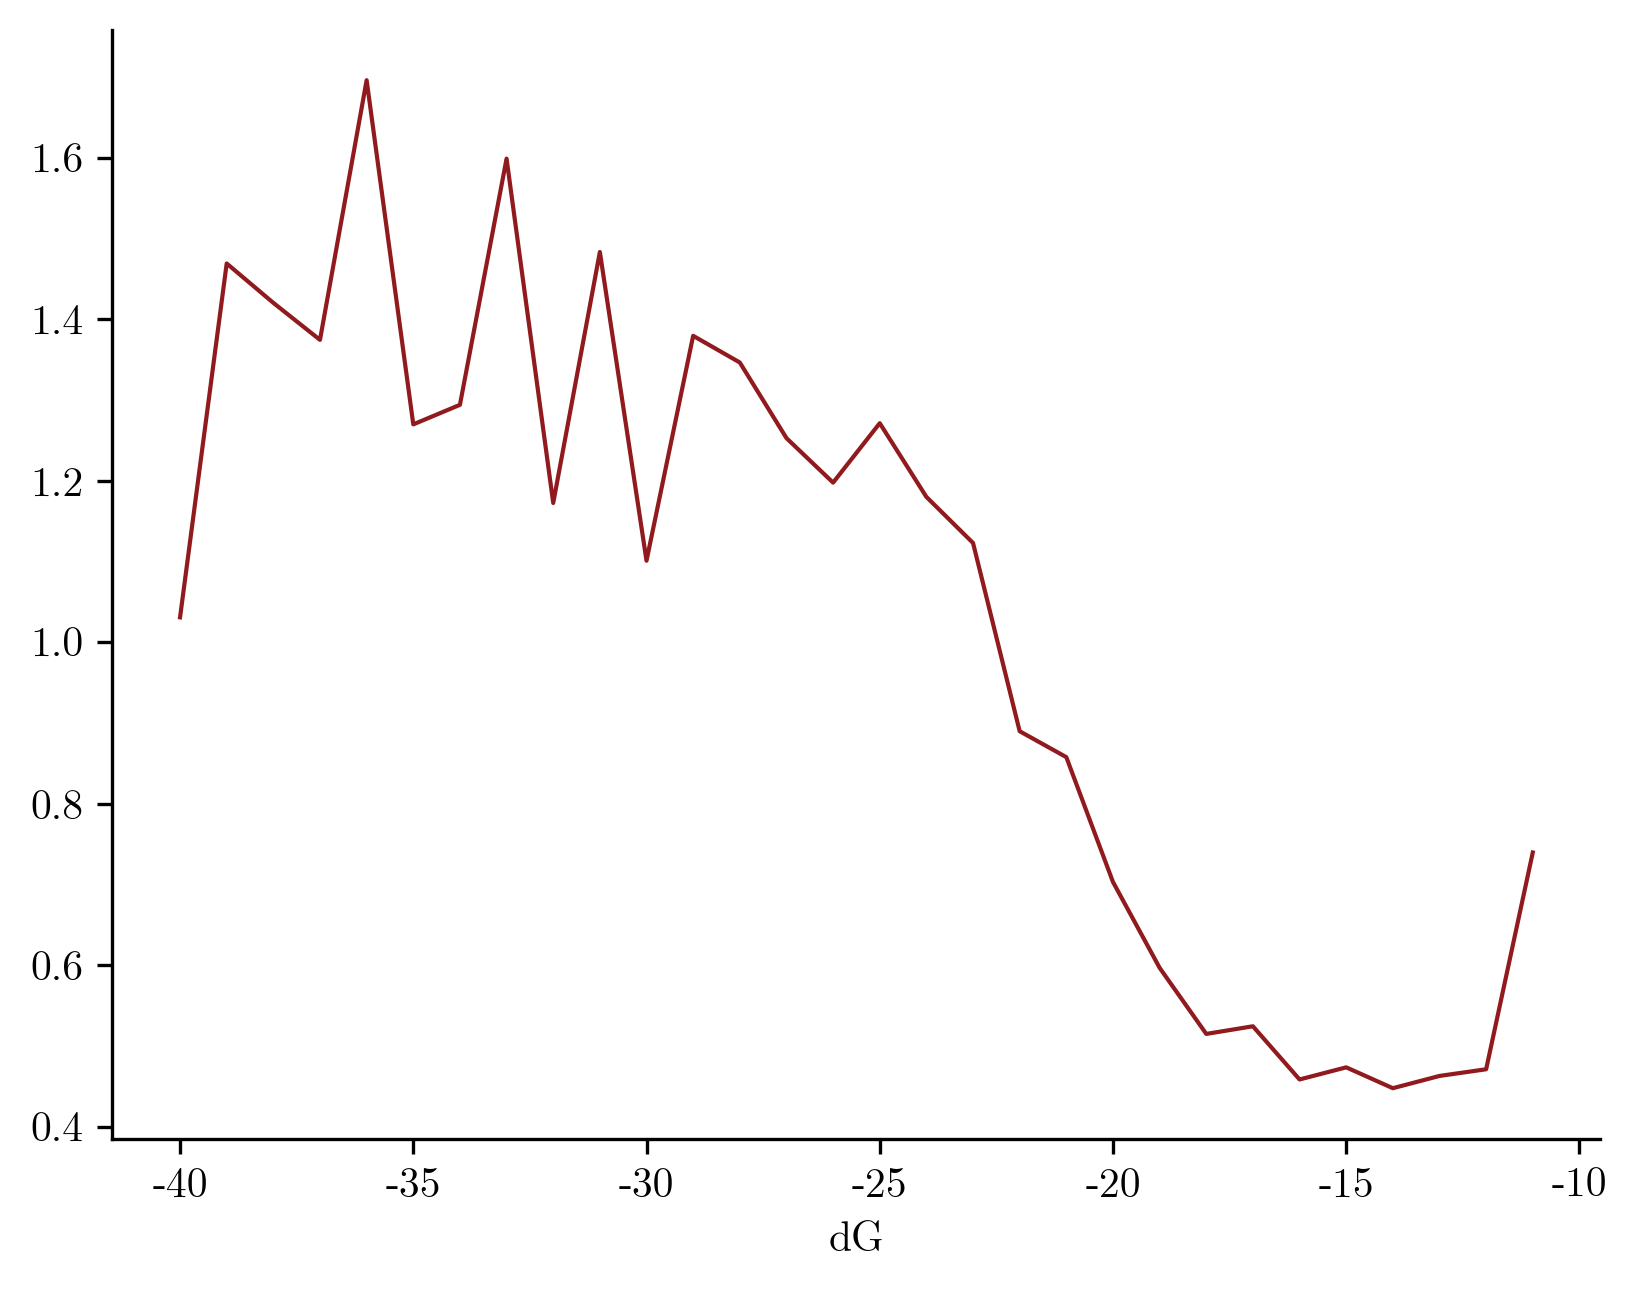

In [26]:
(
    (dGs_reweighted_full.dG - dGs_reweighted_singular.dG)
    [(dGs_reweighted_full.dG >= DG_WINDOW[0]) & (dGs_reweighted_full.dG <= DG_WINDOW[1])]
    .groupby(dGs_reweighted_full.dG.round(0))
    .apply(lambda sub: np.mean(sub**2)**0.5)
).plot()

In [ ]:
system_id = 'wdr5-mll2'
subset_full = dGs_reweighted_full[dGs_reweighted_full['System'] == system_id]
subset_unref = dGs_reweighted_initial[dGs_reweighted_initial['System'] == system_id]
subset_sing = dGs_reweighted_singular[dGs_reweighted_singular['System'] == system_id]

dGs_system = dGs[dGs['System'] == system_id]
dGs_converged = dGs_system[~dGs_system.traj_never_binds & ~dGs_system.traj_never_unbinds]
dGs_unconverged = dGs_system[dGs_system.traj_never_binds | dGs_system.traj_never_unbinds]
plt.errorbar(
    dGs_converged['eps_go'],
    dGs_converged['dG'],
    np.stack([dGs_converged['dG'] - dGs_converged['dG-1SEM'],  dGs_converged['dG+1SEM'] - dGs_converged['dG']]),
    color=visualisation.ku_red, ms=2, capsize=1, elinewidth=0.5, lw=0.5, fmt = 's', 
    label="Simulations used for final reweighting"
)
dGs_initial = dGs_converged[dGs_converged.eps_go.isin(range(6))]
plt.errorbar(
    dGs_initial['eps_go'],
    dGs_initial['dG'],
    np.stack([dGs_initial['dG'] - dGs_initial['dG-1SEM'],  dGs_initial['dG+1SEM'] - dGs_initial['dG']]),
    color=visualisation.green, ms=2, capsize=1, elinewidth=0.5, lw=0.5, fmt = 's', 
    label="Simulations used for initial reweighting"
)
dGs_inrange = dGs_converged[(dGs_converged.dG >= DG_WINDOW[0]) & (dGs_converged.dG <= DG_WINDOW[1])]
if len(dGs_inrange) == 0:
    dGs_inrange = dGs_converged
dGs_singular = dGs_inrange.iloc[[np.argmax(dGs_inrange.traj_transitions)]]
plt.errorbar(
    dGs_singular['eps_go'],
    dGs_singular['dG'],
    np.stack([dGs_singular['dG'] - dGs_singular['dG-1SEM'],  dGs_singular['dG+1SEM'] - dGs_singular['dG']]),
    color=visualisation.blue, ms=2, capsize=1, elinewidth=0.5, lw=0.5, fmt = 's', 
    label="Simulations used for singular reweighting"
)
plt.plot(subset_full.eps_go, subset_full.dG, label='Full', color=visualisation.ku_red, ls='dotted')
plt.plot(subset_unref.eps_go, subset_unref.dG, label='initial', color=visualisation.green, ls='dotted')
plt.plot(subset_sing.eps_go, subset_sing.dG, label='Singular', color=visualisation.blue, ls='dotted')

plt.legend()
xlim = plt.xlim(-0.05,5.05)
ylim = plt.ylim(-50,10)

## Reweighting onto edited contact graphs

In [ ]:
DG_GRID     = np.round(np.arange(round(DG_WINDOW[0]+constants.R*298.15*np.log(10), 1), round(DG_WINDOW[1], 1) + 0.1, 0.1), 1)
GRAPH_DIR   = 'data/synthetic/graph_variants'        # pre-generated edited contact tables (system__variant.txt)

# Parents are whichever systems already have edited contact tables on disk in GRAPH_DIR --
# a curated subset of the library (some systems were excluded upstream, e.g. for poor fPCA
# behaviour or being feature-space outliers; see data/synthetic/features.csv for the set kept).
converged = dGs[~dGs.traj_never_binds & ~dGs.traj_never_unbinds]
variant_names = {}
for fname in sorted(os.listdir(GRAPH_DIR)):
    if not fname.endswith('.txt'):
        continue
    system_id, variant = fname[:-4].split('__')
    variant_names.setdefault(system_id, []).append(variant)

PARENTS = [s for s in variant_names if s in set(sims.System) and s in q_bounds.index and s in set(converged.System)]
skipped = sorted(set(variant_names) - set(PARENTS))

print(f'{len(PARENTS)} parents with pre-generated variants in {GRAPH_DIR} '
      f'({sum(len(variant_names[s]) for s in PARENTS)} variant files)')
if skipped:
    print(f'skipped (missing sims/q_bounds/converged coverage): {skipped}')
print(f'dG grid {DG_GRID[0]:.1f}..{DG_GRID[-1]:.1f} kJ/mol in {len(DG_GRID)} steps')


In [ ]:
from collections import defaultdict, deque


def keep_mask_from_variant(parent_contacts, variant_contacts):
    """Reconstruct the boolean keep-mask an edited contact table encodes.

    Each ``system__variant.txt`` in ``GRAPH_DIR`` is a subset of the parent's
    ``specific_interactions.txt`` rows, written out in the parent's original row order.
    Matching by ``(chain, residue)`` key therefore recovers exactly which parent rows
    survived; a deque per key makes this exact even if a key repeats, since each variant
    occurrence consumes one matching parent occurrence in order.

    Parameters
    ----------
    parent_contacts, variant_contacts : pandas.DataFrame
        Output of :func:`utils.parse_specific_interactions` for the parent and one of its
        edited variants.

    Returns
    -------
    numpy.ndarray
        Boolean mask of length ``len(parent_contacts)``, ``True`` where that parent contact
        survives in ``variant_contacts``.
    """
    key_cols = ['Acceptor chain', 'Acceptor residue', 'Donor chain', 'Donor residue']
    positions = defaultdict(deque)
    for i, key in enumerate(parent_contacts[key_cols].itertuples(index=False, name=None)):
        positions[key].append(i)
    mask = np.zeros(len(parent_contacts), dtype=bool)
    for key in variant_contacts[key_cols].itertuples(index=False, name=None):
        if not positions[key]:
            raise ValueError(f'variant contact {key} not found in parent (or already matched)')
        mask[positions[key].popleft()] = True
    return mask


# Load each parent's native contact table once, then recover every sibling variant's keep-mask
# from its edited table already on disk. 'parent' (keep=None) carries the unedited graph through
# the same code path, so it doubles as a check against dGs_reweighted_full.
graph_variants, parent_n_contacts = {}, {}
for system_id in PARENTS:
    path = sims[sims.System == system_id]['Path'].iloc[0]
    contacts = utils.parse_specific_interactions(f'{path}/specific_interactions.txt')
    parent_n_contacts[system_id] = len(contacts)

    masks = {'parent': None}
    for variant in variant_names[system_id]:
        variant_contacts = utils.parse_specific_interactions(f'{GRAPH_DIR}/{system_id}__{variant}.txt')
        masks[variant] = keep_mask_from_variant(contacts, variant_contacts)
    graph_variants[system_id] = masks

    tiers = pd.Series([v.rstrip('0123456789') for v in variant_names[system_id]]).value_counts().to_dict()
    print(f'{system_id:22} {len(contacts):3d} contacts -> {len(masks)-1:3d} variants {tiers}')


In [ ]:
# Trajectories are read and MBAR solved ONCE per parent, then every variant is evaluated
# against that single estimator -- the whole economy of the approach, since the MBAR solve
# dominates and each parent spawns tens of graphs.
GRID         = np.round(np.arange(0.0, 10.001, 0.05), 2)
dGs_synthetic = {}
with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
    futures = {
        executor.submit(
            mbar.reweight_subgraph_system, system_id,
            converged[converged.System == system_id], sims, q_bounds[system_id], GRID, keeps,
            stride=STRIDE, temperature=TEMPERATURE,
        ): system_id
        for system_id, keeps in graph_variants.items()
    }
    for future in tqdm(as_completed(futures), total=len(futures)):
        dGs_synthetic[futures[future]] = future.result()

dGs_synthetic = pd.concat(dGs_synthetic.values(), ignore_index=True)
dGs_synthetic = dGs_synthetic.sort_values(['System', 'variant', 'eps_go'], kind='stable')  # completion order is not deterministic

# The 'parent' variant is the unedited graph, so it must land on the production curve.
parent_curves = dGs_synthetic[dGs_synthetic.variant == 'parent'].set_index(['System', 'eps_go']).dG
reference = pd.read_csv('data/analysis/dGs_reweighted_full.csv').set_index(['System', 'eps_go']).dG
shared = parent_curves.index.intersection(reference.index)
deviation = (parent_curves[shared] - reference[shared]).abs()
resolved = deviation[np.isfinite(deviation)]
print(f'{len(dGs_synthetic)} rows | parent-vs-production max |ddG| {resolved.max():.2e} kJ/mol '
      f'over {len(resolved)} resolved points')

In [ ]:
keep_idxs = []
for (system_id, variant_id), subset in dGs_synthetic.groupby(['System', 'variant']):
    if subset.dG.min() > DG_WINDOW[0]  or subset.dG.max() < DG_WINDOW[1]:
        continue
    #subset = subset[(subset.dG >= DG_WINDOW[0]) & (subset.dG <= DG_WINDOW[1])]
    keep_idxs += [*subset.index]
dGs_synthetic.loc[keep_idxs].to_csv('data/synthetic/dGs_reweighted_full.csv', index=False)

In [ ]:
dGs_reweighted_full = pd.read_csv('data/analysis/dGs_reweighted_full.csv')
for system_id, sys_subset in dGs_synthetic.loc[keep_idxs].groupby('System'):
    for variant, var_subset in sys_subset.groupby('variant'):
        plt.plot(var_subset['eps_go'], var_subset['dG'], lw=.5, color=visualisation.light_red, alpha=.1)
    par_subset = dGs_reweighted_full[dGs_reweighted_full['System'] == system_id]
    plt.plot(par_subset['eps_go'], par_subset['dG'], lw=1, color=visualisation.ku_red, alpha=1)

# SLiM range
xlim = plt.xlim()
plt.axhspan(*DG_WINDOW, color=visualisation.light_blue, alpha=0.2)
for Kd in np.geomspace(1,1e-12,13):
    dG = slim.dG(Kd)
    if (dG >= DG_WINDOW[0]) & (dG <= DG_WINDOW[-1]):
        plt.axhline(dG, *xlim, color=visualisation.light_blue, alpha=0.5, ls='dashed', lw=.5)

# Decorations
ylim = plt.ylim(-50,10)
plt.ylabel(r'SLiM Affinity ΔG° [kJ/mol]')
plt.xlabel(r'$\text{G}\bar{\text{o}}$ potential well depth $\varepsilon_{\text{G}\bar{\text{o}}}$ [kJ/mol]')
plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
plt.grid(which='major', alpha=0.3, linewidth=0.5)
plt.grid(which='minor', alpha=0.1, linewidth=0.2)

In [ ]:
# Invert each variant to eps_go(dG) on the modelling grid, keeping only what the sampling supports.
#
# Two filters, both load-bearing. N_eff_minor drops the points where the reweighting has no
# minor state left to resolve. Full grid coverage is then required rather than preferred: the
# fPCA target encoder in 6_modelling is a plain SVD, so one NaN in one curve poisons the whole
# basis -- a partially covered child must be dropped, not imputed.
eps_go_graphs = []
for (system_id, variant), curve in dGs_synthetic.groupby(['System', 'variant'], sort=False):
    reliable = curve[(curve.N_eff_minor >= MIN_N_EFF_MINOR) & np.isfinite(curve.dG)]
    reliable = reliable.drop_duplicates('dG').sort_values('dG')
    if len(reliable) < 3:
        continue
    # dG decreases with eps_go, hence the sort; NaN outside the support is what the coverage test reads.
    eps_of_dG = np.interp(DG_GRID, reliable.dG.to_numpy(), reliable.eps_go.to_numpy(),
                          left=np.nan, right=np.nan)
    if not np.isfinite(eps_of_dG).all():
        continue
    mask = graph_variants[system_id][variant]
    eps_go_graphs.append(pd.DataFrame({
        'System': f'{system_id}__{variant}', 'Parent': system_id, 'variant': variant,
        'N_C': parent_n_contacts[system_id] if mask is None else int(mask.sum()),
        'dG': DG_GRID, 'eps_go': eps_of_dG,
    }))

eps_go_graphs = pd.concat(eps_go_graphs, ignore_index=True)
eps_go_graphs.to_csv('data/analysis/eps_go_graphs.csv', index=False)

summary = pd.DataFrame({
    'attempted': pd.Series({s: len(v) for s, v in graph_variants.items()}),
    'usable': eps_go_graphs.groupby('Parent').variant.nunique(),
}).fillna(0).astype(int)
summary['kept'] = (summary.usable / summary.attempted).map('{:.0%}'.format)
summary['N_C range'] = eps_go_graphs.groupby('Parent').N_C.agg(
    lambda n: f'{n.min()}-{n.max()}')
print(summary.sort_values('usable', ascending=False).to_string())
print(f'\n{summary.usable.sum()} usable curves ({summary.usable.sum() - (summary.usable > 0).sum()} edited) '
      f'from {(summary.usable > 0).sum()} families')

In [ ]:
for parent_id, family in tqdm(dGs_synthetic.groupby('System')):

    usable = set(eps_go_graphs[eps_go_graphs.Parent == parent_id].variant)
    n_contacts = {v: (parent_n_contacts[parent_id] if m is None else int(m.sum()))
                  for v, m in graph_variants[parent_id].items()}
    spread = [n_contacts[v] for v in usable] or [parent_n_contacts[parent_id]]
    norm = plt.Normalize(min(spread), parent_n_contacts[parent_id])
    colours = plt.cm.viridis

    for variant, curve in family.groupby('variant'):
        if variant == 'parent':
            continue
        # Only the reliable stretch is drawn solid: an edited graph's curve is honest
        # exactly as far as its minor state is still resolved.
        reliable = curve[(curve.N_eff_minor >= MIN_N_EFF_MINOR) & (curve.dG > -50)]
        plt.plot(reliable.eps_go, reliable.dG, lw=0.5, alpha=0.7 if variant in usable else 0.25,
                 ls='-' if variant in usable else 'dotted',
                 color=colours(norm(n_contacts[variant])))

    parent_curve = family[(family.variant == 'parent') & (family.dG > -50)]
    parent_reliable = parent_curve[parent_curve.N_eff_minor >= MIN_N_EFF_MINOR]
    plt.plot(parent_reliable.eps_go, parent_reliable.dG, color=visualisation.ku_red, lw=2,
             label=f'Parent ({parent_n_contacts[parent_id]} contacts)')

    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=colours), ax=plt.gca(),
                 label='Contacts retained')
    plt.axhspan(*DG_WINDOW, color=visualisation.light_blue, alpha=0.2,
                label=r"ΔG°-range for $K_d$ = 10 mM to 100 nM")
    plt.xlim(0, GRID.max())
    plt.ylim(-50, 10)
    plt.ylabel(r'SLiM Affinity ΔG° [kJ/mol]')
    plt.xlabel(r'$\text{G}\bar{\text{o}}$ potential well depth $\varepsilon_{\text{G}\bar{\text{o}}}$ [kJ/mol]')
    plt.grid(which='major', alpha=0.3, linewidth=0.5)
    plt.legend(frameon=False, loc='lower left')
    plt.title(f'{parent_id} — {len(usable)} usable edited graphs of {len(graph_variants[parent_id]) - 1}')
    plt.savefig(f'figs/reweightings/{parent_id}_graphs.png', bbox_inches='tight')
    plt.clf()